In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("../data/raw")
REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(DATA_DIR / "train.csv")
campaign_data = pd.read_csv(DATA_DIR / "campaign_data.csv")

print("Training shape:", train.shape)
print("Campaign data shape:", campaign_data.shape)

display(train.head())
display(train.info())

Training shape: (78369, 5)
Campaign data shape: (28, 4)


,id,campaign_id,coupon_id,customer_id,redemption_status
0,1,13,27,1053,0
1,2,13,116,48,0
2,6,9,635,205,0
3,7,13,644,1050,0
4,9,8,1017,1489,0


<class 'pandas.DataFrame'>
RangeIndex: 78369 entries, 0 to 78368
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   id                 78369 non-null  int64
 1   campaign_id        78369 non-null  int64
 2   coupon_id          78369 non-null  int64
 3   customer_id        78369 non-null  int64
 4   redemption_status  78369 non-null  int64
dtypes: int64(5)
memory usage: 3.0 MB


None

In [2]:
print("Training columns:")
print(train.columns.tolist())

display(train.dtypes)

display(train.describe(include="all").T)

Training columns:
['id', 'campaign_id', 'coupon_id', 'customer_id', 'redemption_status']


id                   int64
campaign_id          int64
coupon_id            int64
customer_id          int64
redemption_status    int64
dtype: object

,count,mean,std,min,25%,50%,75%,max
id,78369.0,64347.975449,37126.440855,1.0,32260.0,64318.0,96577.0,128595.0
campaign_id,78369.0,13.974441,8.019215,1.0,8.0,13.0,13.0,30.0
coupon_id,78369.0,566.363243,329.966054,1.0,280.0,597.0,857.0,1115.0
customer_id,78369.0,787.451888,456.811339,1.0,399.0,781.0,1190.0,1582.0
redemption_status,78369.0,0.009302,0.095999,0.0,0.0,0.0,0.0,1.0


In [3]:
for col in train.columns:
    print(f"\nColumn: {col}")
    print("Unique values:", train[col].nunique())
    print("Missing values:", train[col].isna().sum())

    if train[col].nunique() <= 20:
        print(train[col].value_counts(dropna=False))


Column: id
Unique values: 78369
Missing values: 0

Column: campaign_id
Unique values: 18
Missing values: 0
campaign_id
13    22606
8     22555
30     6467
26     6056
29     3895
9      3168
11     2782
12     2550
5      1827
10     1723
7      1584
4       972
2       768
28      476
3       408
27      324
1       143
6        65
Name: count, dtype: int64

Column: coupon_id
Unique values: 866
Missing values: 0

Column: customer_id
Unique values: 1428
Missing values: 0

Column: redemption_status
Unique values: 2
Missing values: 0
redemption_status
0    77640
1      729
Name: count, dtype: int64


In [4]:
print("Training dataset columns:")
print(train.columns.tolist())

print("\nTarget distribution:")
display(train["redemption_status"].value_counts())

print("\nTarget distribution (%):")
display(
    (train["redemption_status"].value_counts(normalize=True) * 100)
    .round(2)
)

Training dataset columns:
['id', 'campaign_id', 'coupon_id', 'customer_id', 'redemption_status']

Target distribution:


redemption_status
0    77640
1      729
Name: count, dtype: int64


Target distribution (%):


redemption_status
0    99.07
1     0.93
Name: proportion, dtype: float64

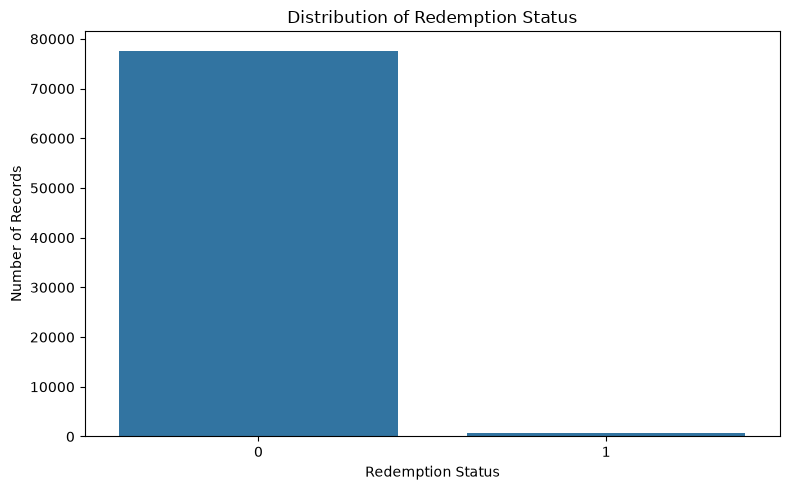

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x="redemption_status"
)

plt.title("Distribution of Redemption Status")
plt.xlabel("Redemption Status")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [6]:
campaign_redemption = (
    train.groupby("campaign_id")
    .agg(
        total_records=("redemption_status", "size"),
        redemptions=("redemption_status", "sum"),
        redemption_rate=("redemption_status", "mean")
    )
    .reset_index()
)

campaign_redemption["redemption_rate_pct"] = (
    campaign_redemption["redemption_rate"] * 100
).round(2)

display(
    campaign_redemption.sort_values(
        "redemption_rate_pct",
        ascending=False
    )
)

,campaign_id,total_records,redemptions,redemption_rate,redemption_rate_pct
5,6,65,1,0.015385,1.54
12,13,22606,346,0.015306,1.53
7,8,22555,199,0.008823,0.88
13,26,6056,52,0.008587,0.86
8,9,3168,23,0.007260,0.73
3,4,972,7,0.007202,0.72
0,1,143,1,0.006993,0.70
1,2,768,5,0.006510,0.65
17,30,6467,39,0.006031,0.60
2,3,408,2,0.004902,0.49


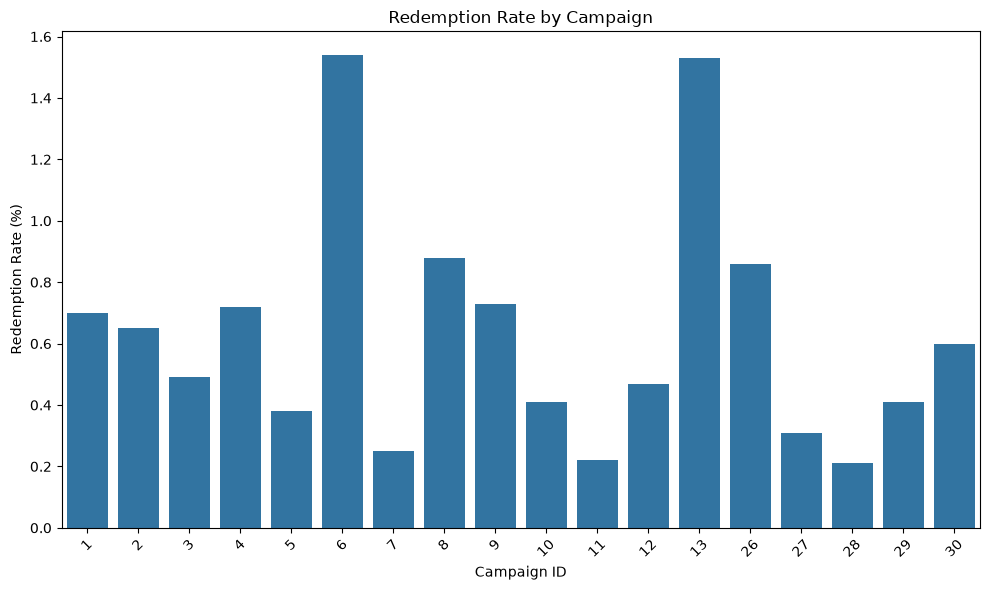

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = campaign_redemption.sort_values(
    "redemption_rate_pct",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x="campaign_id",
    y="redemption_rate_pct"
)

plt.title("Redemption Rate by Campaign")
plt.xlabel("Campaign ID")
plt.ylabel("Redemption Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
campaign_type_analysis = train.merge(
    campaign_data[["campaign_id", "campaign_type"]],
    on="campaign_id",
    how="left"
)

type_redemption = (
    campaign_type_analysis
    .groupby("campaign_type")
    .agg(
        total_records=("redemption_status", "size"),
        total_redemptions=("redemption_status", "sum"),
        redemption_rate=("redemption_status", "mean")
    )
    .reset_index()
)

type_redemption["redemption_rate_pct"] = (
    type_redemption["redemption_rate"] * 100
).round(2)

display(type_redemption)

,campaign_type,total_records,total_redemptions,redemption_rate,redemption_rate_pct
0,X,57684,636,0.011026,1.10
1,Y,20685,93,0.004496,0.45


In [9]:
top_campaigns = campaign_redemption.sort_values(
    "redemption_rate_pct", ascending=False
).head(10)

display(top_campaigns)

,campaign_id,total_records,redemptions,redemption_rate,redemption_rate_pct
5,6,65,1,0.015385,1.54
12,13,22606,346,0.015306,1.53
7,8,22555,199,0.008823,0.88
13,26,6056,52,0.008587,0.86
8,9,3168,23,0.007260,0.73
3,4,972,7,0.007202,0.72
0,1,143,1,0.006993,0.70
1,2,768,5,0.006510,0.65
17,30,6467,39,0.006031,0.60
2,3,408,2,0.004902,0.49


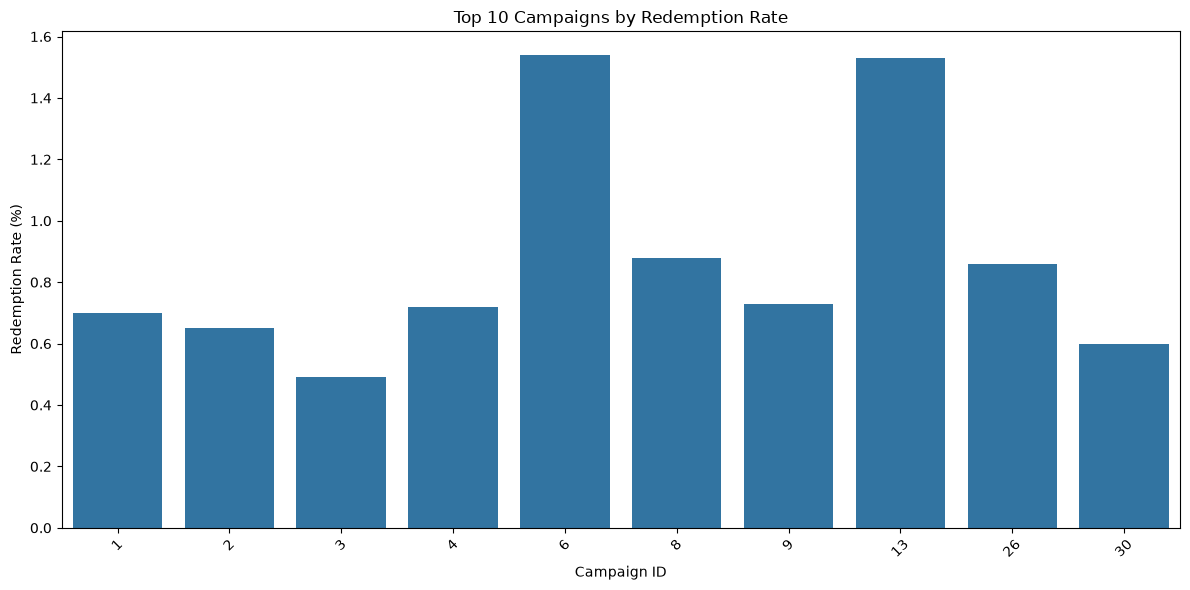

In [10]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_campaigns,
    x="campaign_id",
    y="redemption_rate_pct"
)

plt.title("Top 10 Campaigns by Redemption Rate")
plt.xlabel("Campaign ID")
plt.ylabel("Redemption Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
campaign_redemption.to_csv(
    REPORT_DIR / "day04_campaign_redemption.csv",
    index=False
)

type_redemption.to_csv(
    REPORT_DIR / "day04_campaign_type_analysis.csv",
    index=False
)

top_campaigns.to_csv(
    REPORT_DIR / "day04_top_campaigns.csv",
    index=False
)

print("Day 4 analysis reports saved successfully!")

Day 4 analysis reports saved successfully!
